In [ ]:
import openmc
import numpy as np
import matplotlib.pyplot as plt
from inputs import *

/home/jpontes/miniforge/envs/openmc-env/lib/python3.13/site-packages/openmc/material.py:825: UserWarning: A uranium enrichment of 19.75 was given for Material ID="1". OpenMC assumes the U234/U235 mass ratio is constant at 0.008, which is only valid at low enrichments. Consider setting the isotopic composition manually for enrichments over 5%.
  warnings.warn(msg)


In [ ]:
pebble_diameter = 6
pebble_centers = np.loadtxt('../PackingPebbles/DEM/pb53k/pb53k.dat')*pebble_diameter

In [3]:
# One pebble universe centered at the origin, reused for every pebble
pebble_inner_sphere = openmc.Sphere(r = inner_graphite_radius)
fuel_sphere = openmc.Sphere(r = fuel_region_radius)

pebble_inner_cell = openmc.Cell(fill = graphite_low, region = -pebble_inner_sphere)
pebble_fuel_cell = openmc.Cell(fill = pebble_homog, region = -fuel_sphere & +pebble_inner_sphere)
pebble_outer_cell = openmc.Cell(fill = graphite, region = +fuel_sphere) # bounded by the pebble's outer sphere
pebble_universe = openmc.Universe(cells = [pebble_inner_cell, pebble_fuel_cell, pebble_outer_cell])

pebbles = [openmc.model.TRISO(outer_graphite_radius, pebble_universe, center) for center in pebble_centers]

In [ ]:
core_upper = openmc.ZPlane(z0 = 250, boundary_type = 'vacuum')
core_lower = openmc.ZPlane(z0 = 0, boundary_type = 'vacuum')
core_cylinder = openmc.ZCylinder(r = core_cylinder_radius, boundary_type= 'vacuum')

# Bin pebbles into a lattice so each lookup only checks the pebbles near the particle
lattice_shape = (26, 26, 25)
lower_left = (-core_cylinder_radius, -core_cylinder_radius, 0.)
pitch = (2*core_cylinder_radius/lattice_shape[0], 2*core_cylinder_radius/lattice_shape[1], 250/lattice_shape[2])
pebble_lattice = openmc.model.create_triso_lattice(pebbles, lower_left, pitch, lattice_shape, FLiBe)

In [5]:
core_cell = openmc.Cell(fill = pebble_lattice, region = -core_cylinder & +core_lower & -core_upper)

In [6]:
pebble_bed_universe = openmc.Universe(cells = [core_cell])

In [7]:
colors_dict = {FLiBe:'green', pebble_homog:'red', graphite:'lightskyblue', graphite_low:'lightskyblue'}

In [8]:
pebble_bed_universe.plot(basis = 'xy', width = (core_cylinder_radius*2,core_cylinder_radius*2), color_by = 'material', colors= colors_dict)

KeyboardInterrupt: 

In [9]:
geometry = openmc.Geometry(pebble_bed_universe)
geometry.export_to_xml()

materials = openmc.Materials(materials_list)
materials.cross_sections = xs_path
materials.export_to_xml()

In [10]:
settings = openmc.Settings()

# Initial particle source:

angular_dist = openmc.stats.Isotropic()

energy_dist = openmc.stats.Watt()

spatial_dist = openmc.stats.CylindricalIndependent(r = openmc.stats.PowerLaw(0, core_cylinder_radius, 1), phi = openmc.stats.Uniform(0, 2*np.pi), z = openmc.stats.Uniform(0, 200))

origin = openmc.IndependentSource(space = spatial_dist, angle = angular_dist, energy = energy_dist, particle = 'neutron', constraints = {'fissionable': True})

settings.source = origin

# Simulation parameters:

# Shannon entropy mesh:

entropy_mesh = openmc.RegularMesh(name = 'Entropy Mesh')
entropy_mesh.lower_left = [-core_cylinder_radius, -core_cylinder_radius, 0]
entropy_mesh.upper_right = [core_cylinder_radius, core_cylinder_radius, 250]
entropy_mesh.dimension = [10, 10, 50]
settings.entropy_mesh = entropy_mesh

# Simulation parameters:

settings.run_mode = 'eigenvalue'
settings.photon_transport = False
settings.energy_mode = 'continuous-energy'

settings.temperature = {'default': T_avg, 'method': 'interpolation','range':[250,2500], 'multipole': False}#True?
settings.resonance_scattering = {'enable': True, 'method': 'rvs', 'energy_min': 0.01, 'energy_max': 1000.0}

settings.particles = 100000 
settings.generations_per_batch = 1
settings.inactive = 50 #100
settings.batches = 150 #600
# Skip per-material-cell offset tables (otherwise ~10+ GB for this many cells)
settings.material_cell_offsets = False
settings.export_to_xml()

<Axes: xlabel='y [cm]', ylabel='z [cm]'>

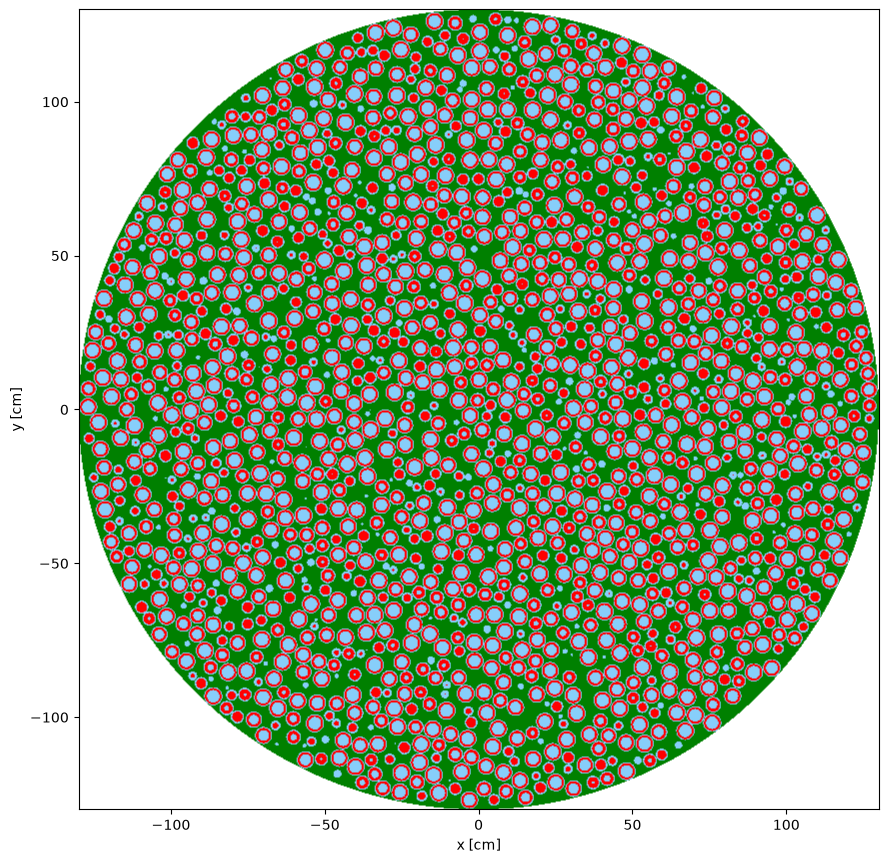

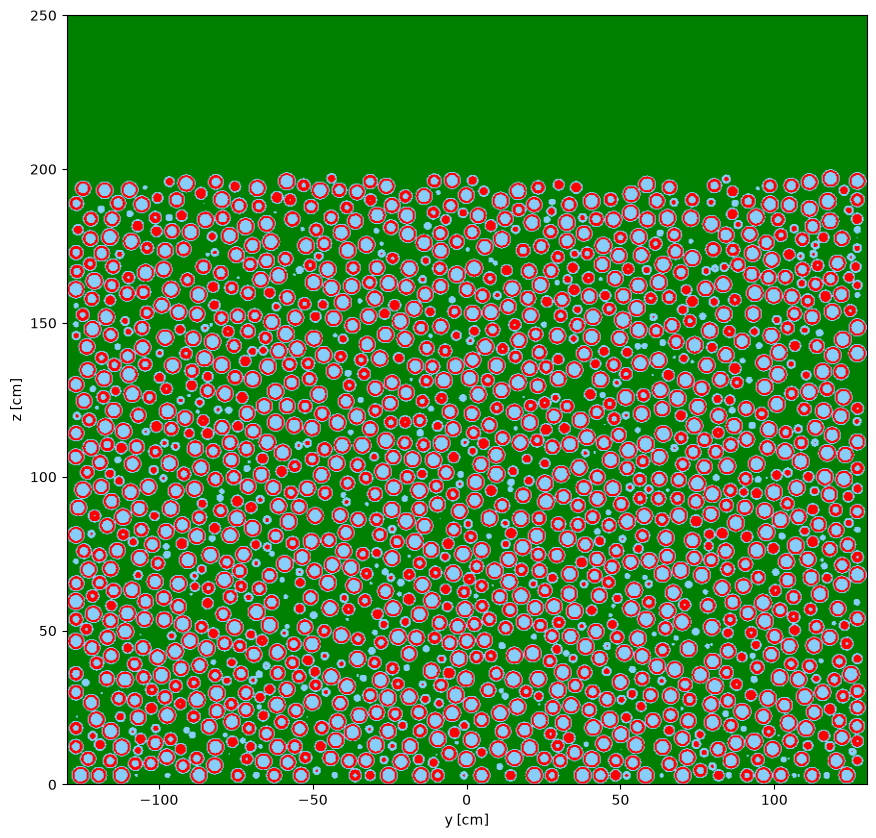

In [11]:
model = openmc.Model(geometry=geometry, materials=materials, settings=settings)

model.plot(basis='xy', origin=(0, 0, 100), width=(2*core_cylinder_radius, 2*core_cylinder_radius),
           pixels=(800, 800), color_by='material', colors=colors_dict)

model.plot(basis='yz', origin=(0, 0, 125), width=(2*core_cylinder_radius, 250),
           pixels=(800, 800), color_by='material', colors=colors_dict)
